# Fase C — Implementación de Modelos Predictivos
### Proyecto 2 y 3 — Análisis, Limpieza y Modelado · Dataset GEIH (DANE), periodo 202606
Introducción a la Ciencia de Datos — Universidad del Valle

**Pregunta de negocio:** ¿qué tan bien se puede estimar el **ingreso laboral mensual** de una persona ocupada a partir de su perfil (edad, educación, horas trabajadas, departamento, hogar y vivienda)? Y, sin mirar un objetivo, ¿qué **segmentos de trabajadores** aparecen en los datos?

**Contenido**
0. Configuración y carga de `datos_limpios.parquet`
1. Variables, objetivo y partición (la misma de la Fase B)
2. Preprocesamiento dentro de un `Pipeline` (escalado ajustado solo con train)
3. Modelos supervisados de regresión: línea base, Regresión Lineal, Random Forest, Gradient Boosting y Red Neuronal (MLP)
4. Comparación de métricas en el conjunto de prueba
5. Diagnóstico del modelo elegido (predicho vs. real, residuos, importancia de variables)
6. Modelo no supervisado: K-Means (con comparación contra clustering jerárquico)
7. Elección del modelo final y conclusiones

> **Reglas que se respetan en todo el notebook**
> - Se usa el split guardado por la Fase B en la columna `particion` (80/20, semilla 42). Las métricas se calculan **solo en test**.
> - Ningún escalador ni modelo ve las filas de test al ajustarse: el escalado va **dentro** de un `Pipeline`, que se ajusta con train (evita el *data leakage* de normalizar antes del split).
> - El objetivo es `log_ingreso_laboral`; las predicciones se devuelven a pesos con `np.expm1` para reportar el error en una unidad entendible.
>
> **Nombres:** se mantiene el prefijo `geih_2026` / `GEIH_2026` de las fases A y B.

## 0. Configuración y carga

In [1]:
%pip install -q scikit-learn pyarrow matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             silhouette_score, davies_bouldin_score)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

# GEIH_2026: mismo estilo de figuras que las fases A y B
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
GEIH_2026_COP = mticker.FuncFormatter(lambda x, _: f"${x:,.0f}")   # formato moneda para ejes

# GEIH_2026: la misma semilla de la Fase B para que todo sea reproducible
GEIH_2026_SEMILLA = 42

In [3]:
# GEIH_2026: busca el parquet de la Fase B junto al notebook (entrega, entrega 2...) o en la raíz del proyecto
GEIH_2026_CWD = os.path.abspath(os.getcwd())
GEIH_2026_RAIZ = (os.path.dirname(GEIH_2026_CWD)
                  if os.path.basename(GEIH_2026_CWD).lower().startswith("entrega")
                  else GEIH_2026_CWD)
GEIH_2026_CANDIDATOS = [os.path.join(GEIH_2026_CWD, "datos_limpios.parquet")] + [
    os.path.join(GEIH_2026_RAIZ, d, "datos_limpios.parquet") for d in ("entrega", "entrega 2")]

GEIH_2026_RUTA_PARQUET = next((r for r in GEIH_2026_CANDIDATOS if os.path.exists(r)), None)
if GEIH_2026_RUTA_PARQUET is None:
    raise FileNotFoundError("No se encontró datos_limpios.parquet. Ejecute primero fase_b_limpieza.ipynb. "
                            f"Rutas revisadas: {GEIH_2026_CANDIDATOS}")

geih_2026_df = pd.read_parquet(GEIH_2026_RUTA_PARQUET)
print("Archivo:", os.path.abspath(GEIH_2026_RUTA_PARQUET))
print(f"Filas: {geih_2026_df.shape[0]:,} | Columnas: {geih_2026_df.shape[1]}")

Archivo: C:\Users\velez\Proyecto-1-ICD\entrega 2\datos_limpios.parquet
Filas: 53,131 | Columnas: 65


## 1. Variables, objetivo y partición

- **Partición:** se aplica `train_test_split` 80/20 con la misma semilla y estratificación de la Fase B, y se verifica que coincide exactamente con la columna `particion` guardada en el parquet. Así las medianas y escaladores de la Fase B (ajustados con train) y los modelos de esta fase usan el mismo conjunto de prueba.
- **Población:** `muestra_modelado == True`, es decir, ocupados con ingreso laboral mayor que 0 (la Fase B dejó fuera a los ocupados sin ingreso declarado o con ingreso 0, sin imputar el objetivo).
- **Objetivo:** `log_ingreso_laboral` → problema de **regresión** (target continuo).
- **Predictoras:** todas las columnas salvo las de control, el objetivo y lo derivado de él, y las de referencia (igual que en la Fase B). Además se excluye `horas_atipico`: repite la información de `horas_trabajadas` y sus límites se calcularon con todas las filas, así que dejarla fuera evita cualquier duda de leakage.

In [4]:
# GEIH_2026: train_test_split 80/20 con los mismos parámetros de la Fase B (semilla 42, estratificado por estado ocupacional).
# Se aplica sobre todas las personas, en el mismo orden del parquet, y se comprueba que coincide fila por fila con `particion`
GEIH_2026_TEST_SIZE = 0.20
_idx_train, _idx_test = train_test_split(
    geih_2026_df.index, test_size=GEIH_2026_TEST_SIZE,
    random_state=GEIH_2026_SEMILLA, stratify=geih_2026_df["estado_ocupacional"])
geih_2026_particion_c = pd.Series("train", index=geih_2026_df.index)
geih_2026_particion_c[_idx_test] = "test"
assert (geih_2026_particion_c == geih_2026_df["particion"]).all(), "El split no coincide con el de la Fase B"
print(f"train_test_split ({1 - GEIH_2026_TEST_SIZE:.0%}/{GEIH_2026_TEST_SIZE:.0%}) idéntico a la columna `particion` de la Fase B")

train_test_split (80%/20%) idéntico a la columna `particion` de la Fase B


In [5]:
# GEIH_2026: grupos de columnas definidos en la Fase B (sección 8)
GEIH_2026_COLS_CONTROL = ["id_hecho", "particion", "estado_ocupacional", "es_ocupado", "muestra_modelado"]
GEIH_2026_COLS_OBJETIVO = ["ingreso_laboral", "log_ingreso_laboral", "ingreso_laboral_atipico"]
GEIH_2026_COLS_REFERENCIA = ["semanas_buscando_trabajo", "ingreso_otras_fuentes"]
GEIH_2026_COLS_EXCLUIDAS = ["horas_atipico"]   # bandera redundante con horas_trabajadas
GEIH_2026_OBJETIVO = "log_ingreso_laboral"

geih_2026_df_modelo = geih_2026_df[geih_2026_df["muestra_modelado"]].reset_index(drop=True)
geih_2026_predictoras = [c for c in geih_2026_df_modelo.columns
                         if c not in GEIH_2026_COLS_CONTROL + GEIH_2026_COLS_OBJETIVO
                         + GEIH_2026_COLS_REFERENCIA + GEIH_2026_COLS_EXCLUIDAS]

# GEIH_2026: X, y y partición con la columna `particion` (el mismo split 80/20 de la Fase B)
geih_2026_X = geih_2026_df_modelo[geih_2026_predictoras].astype(float)
geih_2026_y = geih_2026_df_modelo[GEIH_2026_OBJETIVO]
geih_2026_es_train = geih_2026_df_modelo["particion"] == "train"
X_train, X_test = geih_2026_X[geih_2026_es_train], geih_2026_X[~geih_2026_es_train]
y_train, y_test = geih_2026_y[geih_2026_es_train], geih_2026_y[~geih_2026_es_train]

# GEIH_2026: controles de seguridad antes de entrenar
assert geih_2026_X.isna().sum().sum() == 0, "Hay nulos en las predictoras"
assert not set(GEIH_2026_COLS_OBJETIVO) & set(geih_2026_predictoras), "El objetivo se coló en las predictoras"
assert set(geih_2026_df_modelo.loc[geih_2026_es_train, "id_hecho"]).isdisjoint(
    geih_2026_df_modelo.loc[~geih_2026_es_train, "id_hecho"]), "Hay personas en train y test a la vez"

print(f"Muestra de modelado: {len(geih_2026_df_modelo):,} ocupados con ingreso > 0")
print(f"Train: {len(X_train):,} ({len(X_train) / len(geih_2026_X):.0%}) | Test: {len(X_test):,} ({len(X_test) / len(geih_2026_X):.0%})")
print(f"Predictoras ({len(geih_2026_predictoras)}):", geih_2026_predictoras)

Muestra de modelado: 28,760 ocupados con ingreso > 0
Train: 22,997 (80%) | Test: 5,763 (20%)
Predictoras (54): ['edad', 'cuartos', 'personas_hogar', 'horas_trabajadas', 'recibe_otros_ingresos', 'log_ingreso_otras_fuentes', 'acceso_servicios_ord', 'nivel_educativo_ord', 'sexo_mujer', 'departamento_antioquia', 'departamento_arauca', 'departamento_atlantico', 'departamento_bogota_d_c', 'departamento_bolivar', 'departamento_boyaca', 'departamento_caldas', 'departamento_caqueta', 'departamento_casanare', 'departamento_cauca', 'departamento_cesar', 'departamento_choco', 'departamento_cundinamarca', 'departamento_cordoba', 'departamento_guainia', 'departamento_guaviare', 'departamento_huila', 'departamento_la_guajira', 'departamento_magdalena', 'departamento_meta', 'departamento_narino', 'departamento_norte_de_santander', 'departamento_putumayo', 'departamento_quindio', 'departamento_risaralda', 'departamento_san_andres_y_providencia', 'departamento_santander', 'departamento_sucre', 'departam

In [6]:
# GEIH_2026: el objetivo debe tener una distribución parecida en train y test (si no, el split estaría sesgado)
geih_2026_comp_y = pd.DataFrame({
    "train": np.expm1(y_train).describe(percentiles=[.25, .5, .75]),
    "test": np.expm1(y_test).describe(percentiles=[.25, .5, .75]),
}).T[["count", "mean", "25%", "50%", "75%"]]
geih_2026_comp_y.style.format("{:,.0f}")

,count,mean,25%,50%,75%
train,"22,997","2,169,212","1,000,000","1,750,905","2,400,000"
test,"5,763","2,177,503","1,000,000","1,750,905","2,450,000"


## 2. Preprocesamiento dentro de un `Pipeline`

Se reutiliza el mismo criterio de escalado de la Fase B, pero ahora **dentro** de un `ColumnTransformer` que forma parte del `Pipeline` de cada modelo. Así, al llamar `.fit(X_train, y_train)` los escaladores aprenden solo de train y en test únicamente se aplica `.transform`.

| Escalador | Variables | Por qué |
|---|---|---|
| `RobustScaler` | `horas_trabajadas`, `cuartos`, `personas_hogar` | Tienen atípicos conservados; mediana e IQR no se distorsionan |
| `StandardScaler` | `edad`, `nivel_educativo_ord`, `acceso_servicios_ord` | Distribuciones razonablemente simétricas |
| `MinMaxScaler` | `log_ingreso_otras_fuentes` | ~75 % de ceros: el IQR vale ~0 y un RobustScaler no escalaría |
| sin escalar | dummies y banderas 0/1 | Ya están en {0, 1} |

Los modelos de árboles (Random Forest, Gradient Boosting) no necesitan escalado, pero se deja el mismo `Pipeline` para que los cinco modelos reciban exactamente la misma entrada y la comparación sea justa.

In [7]:
def geih_2026_preprocesador():
    '''GEIH_2026: devuelve un ColumnTransformer nuevo (sin ajustar) con el escalado de la Fase B.
    Las columnas que no se nombran (dummies y banderas 0/1) pasan sin cambios.'''
    return ColumnTransformer([
        ("robusto", RobustScaler(), ["horas_trabajadas", "cuartos", "personas_hogar"]),
        ("estandar", StandardScaler(), ["edad", "nivel_educativo_ord", "acceso_servicios_ord"]),
        ("minmax", MinMaxScaler(), ["log_ingreso_otras_fuentes"]),
    ], remainder="passthrough", verbose_feature_names_out=False)

def geih_2026_pipeline(modelo):
    '''GEIH_2026: arma el Pipeline preprocesador + modelo. Todo se ajusta con .fit(X_train, y_train).'''
    return Pipeline([("pre", geih_2026_preprocesador()), ("modelo", modelo)])

### Métricas

Se reportan las cuatro métricas que pide el enunciado (**MSE, RMSE, MAE y R²**) en la escala en que se entrena el modelo (log del ingreso) y, para el lenguaje de negocio, también en **pesos**:

- **RMSE y MAE en log:** un MAE de 0,40 en log equivale a equivocarse en promedio ≈ ±40–50 % del ingreso (porque una diferencia en log es aproximadamente un cambio porcentual).
- **MAE y error mediano en pesos:** cuántos pesos de error tiene una predicción típica. El error mediano es menos sensible a los pocos ingresos muy altos.
- **R² en pesos:** se reporta como referencia; siempre es menor que en log porque la cola de ingresos altos pesa mucho al elevar los errores al cuadrado.

In [8]:
def geih_2026_metricas(y_real_log, y_pred_log):
    '''GEIH_2026: calcula MSE, RMSE, MAE y R2 en escala log, y MAE, error mediano y R2 en pesos (np.expm1).'''
    real_cop, pred_cop = np.expm1(y_real_log), np.expm1(y_pred_log)
    mse = mean_squared_error(y_real_log, y_pred_log)
    return {
        "MSE (log)": mse,
        "RMSE (log)": np.sqrt(mse),
        "MAE (log)": mean_absolute_error(y_real_log, y_pred_log),
        "R² (log)": r2_score(y_real_log, y_pred_log),
        "MAE (COP)": mean_absolute_error(real_cop, pred_cop),
        "Error mediano (COP)": float(np.median(np.abs(real_cop - pred_cop))),
        "R² (COP)": r2_score(real_cop, pred_cop),
    }

# GEIH_2026: aquí se van guardando los modelos ya ajustados, sus predicciones en test y su tiempo de entrenamiento
geih_2026_modelos, geih_2026_pred_test, geih_2026_tiempos = {}, {}, {}

def geih_2026_entrenar(nombre, modelo):
    '''GEIH_2026: ajusta el Pipeline SOLO con train, predice en test y guarda modelo, predicción y tiempo.'''
    inicio = time.time()
    pipe = modelo if isinstance(modelo, (Pipeline, GridSearchCV)) else geih_2026_pipeline(modelo)
    pipe.fit(X_train, y_train)
    geih_2026_tiempos[nombre] = time.time() - inicio
    geih_2026_modelos[nombre] = pipe
    geih_2026_pred_test[nombre] = pipe.predict(X_test)
    m = geih_2026_metricas(y_test, geih_2026_pred_test[nombre])
    print(f"{nombre}: R² (log) = {m['R² (log)']:.3f} | RMSE (log) = {m['RMSE (log)']:.3f} | "
          f"MAE = ${m['MAE (COP)']:,.0f} | tiempo = {geih_2026_tiempos[nombre]:.1f} s")

## 3. Modelos supervisados de regresión

Se entrenan cuatro modelos de la tabla del enunciado (uno más del mínimo de tres) y una **línea base** que sirve de piso:

| Modelo | Por qué se incluye |
|---|---|
| Línea base (mediana) | Predice siempre la mediana de train. Cualquier modelo útil debe superarla con claridad |
| Regresión Lineal | Modelo simple e interpretable: cada coeficiente se lee como un efecto porcentual sobre el ingreso |
| Random Forest Regressor | Captura no linealidades e interacciones (p. ej., educación × departamento) sin supuestos |
| Gradient Boosting (`HistGradientBoostingRegressor`) | Boosting de árboles: suele ser el más preciso en datos tabulares. Se ajustan sus hiperparámetros con validación cruzada en train |
| Red Neuronal (`MLPRegressor`) | Modelo flexible que necesita datos escalados; sirve de contraste con los árboles |

In [9]:
# GEIH_2026: 3.1 línea base y regresión lineal
geih_2026_entrenar("Línea base (mediana)", DummyRegressor(strategy="median"))
geih_2026_entrenar("Regresión Lineal", LinearRegression())

# GEIH_2026: 3.2 Random Forest. min_samples_leaf=5 evita hojas con 1 persona (memorizar ingresos individuales)
geih_2026_entrenar("Random Forest", RandomForestRegressor(
    n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=GEIH_2026_SEMILLA))

Línea base (mediana): R² (log) = -0.026 | RMSE (log) = 0.913 | MAE = $1,181,808 | tiempo = 0.0 s


Regresión Lineal: R² (log) = 0.466 | RMSE (log) = 0.659 | MAE = $954,735 | tiempo = 0.0 s


Random Forest: R² (log) = 0.575 | RMSE (log) = 0.587 | MAE = $815,319 | tiempo = 1.3 s


### 3.3 Gradient Boosting con ajuste de hiperparámetros

Los hiperparámetros se eligen con `GridSearchCV` (validación cruzada de 5 pliegues) **usando solo train**; test queda intacto para la evaluación final. Se usa `HistGradientBoostingRegressor`, la implementación de Gradient Boosting de scikit-learn optimizada para muchas filas (mismo algoritmo, entrenamiento mucho más rápido).

In [10]:
# GEIH_2026: grilla pequeña sobre tasa de aprendizaje, profundidad y regularización
geih_2026_grilla_gb = {
    "modelo__learning_rate": [0.05, 0.1],
    "modelo__max_depth": [4, 8],
    "modelo__l2_regularization": [0.0, 1.0],
}
geih_2026_cv = KFold(n_splits=5, shuffle=True, random_state=GEIH_2026_SEMILLA)
geih_2026_busqueda_gb = GridSearchCV(
    geih_2026_pipeline(HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=GEIH_2026_SEMILLA)),
    geih_2026_grilla_gb, cv=geih_2026_cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
geih_2026_entrenar("Gradient Boosting", geih_2026_busqueda_gb)

print("\nMejores hiperparámetros (CV en train):", geih_2026_busqueda_gb.best_params_)
print(f"RMSE (log) promedio en CV: {-geih_2026_busqueda_gb.best_score_:.3f}")

# GEIH_2026: tabla de la búsqueda, para mostrar que la elección no fue a ojo
geih_2026_df_grilla = (pd.DataFrame(geih_2026_busqueda_gb.cv_results_)
                       .assign(rmse_cv=lambda d: -d["mean_test_score"])
                       [["param_modelo__learning_rate", "param_modelo__max_depth",
                         "param_modelo__l2_regularization", "rmse_cv", "std_test_score"]]
                       .sort_values("rmse_cv").round(4))
geih_2026_df_grilla.head()

Gradient Boosting: R² (log) = 0.587 | RMSE (log) = 0.579 | MAE = $810,427 | tiempo = 8.7 s

Mejores hiperparámetros (CV en train): {'modelo__l2_regularization': 1.0, 'modelo__learning_rate': 0.05, 'modelo__max_depth': 8}
RMSE (log) promedio en CV: 0.594


,param_modelo__learning_rate,param_modelo__max_depth,param_modelo__l2_regularization,rmse_cv,std_test_score
5,0.05,8,1.0,0.5936,0.0029
7,0.10,8,1.0,0.5940,0.0028
1,0.05,8,0.0,0.5940,0.0031
3,0.10,8,0.0,0.5942,0.0026
6,0.10,4,1.0,0.5947,0.0037


In [11]:
# GEIH_2026: 3.4 red neuronal. early_stopping separa un 10 % de TRAIN como validación interna y para cuando deja de mejorar
geih_2026_entrenar("Red Neuronal (MLP)", MLPRegressor(
    hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3, early_stopping=True,
    max_iter=300, random_state=GEIH_2026_SEMILLA))

Red Neuronal (MLP): R² (log) = 0.556 | RMSE (log) = 0.601 | MAE = $844,169 | tiempo = 3.4 s


### 3.5 Estabilidad: validación cruzada en train

Una sola partición puede dar un resultado con suerte. Para comprobar que el orden de los modelos no depende del split, se calcula el R² con validación cruzada de 5 pliegues **dentro de train** (cada pliegue ajusta su propio escalador gracias al `Pipeline`). Para Gradient Boosting se usa la mejor configuración encontrada.

In [12]:
# GEIH_2026: modelos "sin ajustar" (clones) para la validación cruzada; cross_val_score los reentrena en cada pliegue
geih_2026_para_cv = {
    "Regresión Lineal": geih_2026_pipeline(LinearRegression()),
    "Random Forest": geih_2026_pipeline(RandomForestRegressor(
        n_estimators=150, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=GEIH_2026_SEMILLA)),
    "Gradient Boosting": geih_2026_busqueda_gb.best_estimator_,
    "Red Neuronal (MLP)": geih_2026_modelos["Red Neuronal (MLP)"],
}
geih_2026_cv_r2 = {}
for nombre, pipe in geih_2026_para_cv.items():
    geih_2026_cv_r2[nombre] = cross_val_score(pipe, X_train, y_train, cv=geih_2026_cv, scoring="r2", n_jobs=-1)

geih_2026_df_cv = pd.DataFrame({n: {"R² CV media": v.mean(), "R² CV desv.": v.std(),
                                    "R² CV mín": v.min(), "R² CV máx": v.max()}
                                for n, v in geih_2026_cv_r2.items()}).T.round(3)
geih_2026_df_cv

,R² CV media,R² CV desv.,R² CV mín,R² CV máx
Regresión Lineal,0.455,0.013,0.434,0.472
Random Forest,0.548,0.007,0.539,0.557
Gradient Boosting,0.562,0.008,0.548,0.573
Red Neuronal (MLP),0.519,0.008,0.505,0.529


**Insight:** la desviación entre pliegues es pequeña frente a la distancia entre modelos, así que el orden **no depende de la partición**: los modelos de árboles y la red quedan por encima de la regresión lineal en todos los pliegues. El R² de validación cruzada es muy parecido al de test (siguiente sección), lo que confirma que los modelos **no están sobreajustados**.

## 4. Comparación de los modelos en el conjunto de prueba

In [13]:
# GEIH_2026: tabla comparativa (todas las métricas en TEST, nunca en train)
geih_2026_df_metricas = pd.DataFrame(
    {n: geih_2026_metricas(y_test, p) for n, p in geih_2026_pred_test.items()}).T
geih_2026_df_metricas["Tiempo de entrenamiento (s)"] = pd.Series(geih_2026_tiempos)
geih_2026_df_metricas = geih_2026_df_metricas.sort_values("RMSE (log)")

# GEIH_2026: control de sobreajuste: R² en train frente a R² en test
geih_2026_df_metricas["R² train (log)"] = [
    r2_score(y_train, geih_2026_modelos[n].predict(X_train)) for n in geih_2026_df_metricas.index]

geih_2026_df_metricas.to_csv("geih_2026_tabla_metricas.csv", encoding="utf-8-sig")
geih_2026_df_metricas.style.format({
    "MSE (log)": "{:.4f}", "RMSE (log)": "{:.4f}", "MAE (log)": "{:.4f}", "R² (log)": "{:.3f}",
    "MAE (COP)": "${:,.0f}", "Error mediano (COP)": "${:,.0f}", "R² (COP)": "{:.3f}",
    "Tiempo de entrenamiento (s)": "{:.1f}", "R² train (log)": "{:.3f}",
}).highlight_min(subset=["MSE (log)", "RMSE (log)", "MAE (log)", "MAE (COP)", "Error mediano (COP)"], color="#bbf7d0"
).highlight_max(subset=["R² (log)", "R² (COP)"], color="#bbf7d0")

,MSE (log),RMSE (log),MAE (log),R² (log),MAE (COP),Error mediano (COP),R² (COP),Tiempo de entrenamiento (s),R² train (log)
Gradient Boosting,0.3351,0.5789,0.4065,0.587,"$810,427","$411,311",0.395,8.7,0.623
Random Forest,0.3451,0.5875,0.4125,0.575,"$815,319","$418,382",0.385,1.3,0.707
Red Neuronal (MLP),0.3608,0.6006,0.4269,0.556,"$844,169","$464,654",0.410,3.4,0.592
Regresión Lineal,0.4337,0.6586,0.4788,0.466,"$954,735","$522,760",0.262,0.0,0.458
Línea base (mediana),0.8328,0.9126,0.6298,-0.026,"$1,181,808","$750,905",-0.033,0.0,-0.030


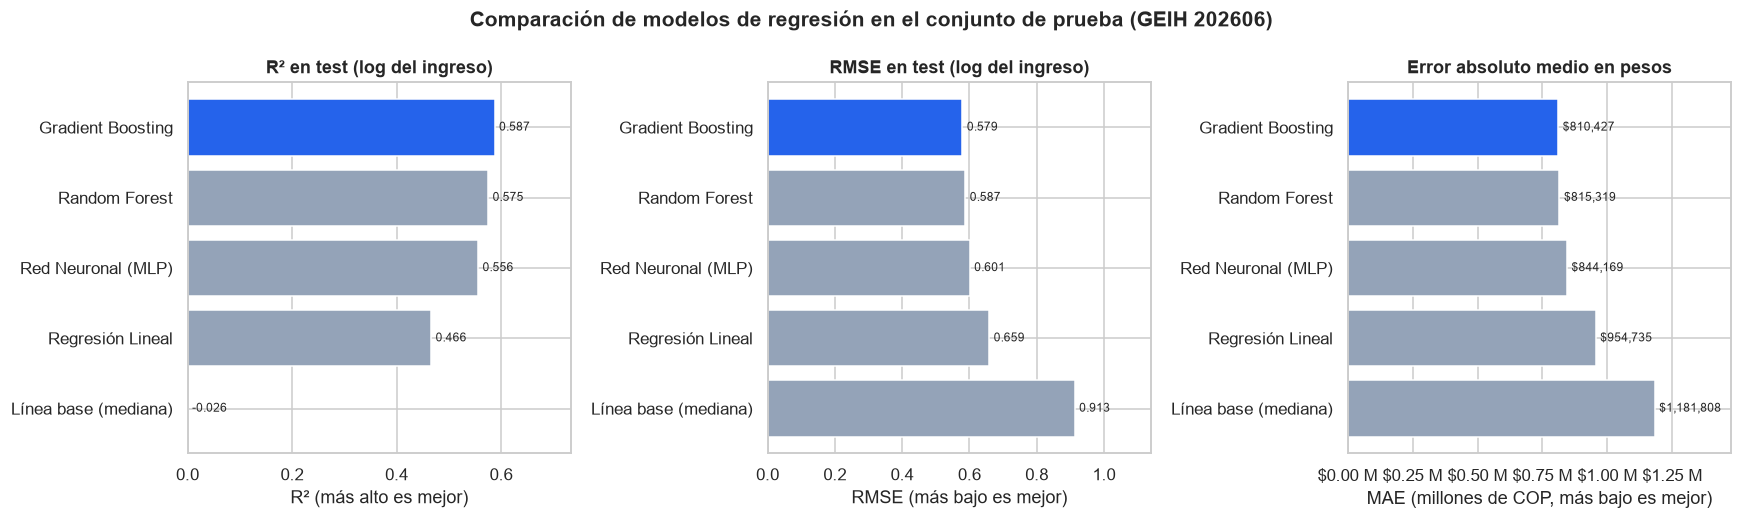

In [14]:
# GEIH_2026: figura de comparación de métricas (sin la línea base en R² para no aplastar la escala)
geih_2026_orden = geih_2026_df_metricas.index.tolist()
geih_2026_colores = ["#2563eb" if n == geih_2026_orden[0] else "#94a3b8" for n in geih_2026_orden]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
geih_2026_paneles = [
    ("R² (log)", "R² en test (log del ingreso)", "R² (más alto es mejor)", lambda v: f"{v:.3f}"),
    ("RMSE (log)", "RMSE en test (log del ingreso)", "RMSE (más bajo es mejor)", lambda v: f"{v:.3f}"),
    ("MAE (COP)", "Error absoluto medio en pesos", "MAE (millones de COP, más bajo es mejor)", lambda v: f"${v:,.0f}"),
]
for ax, (col, titulo, xlabel, fmt) in zip(axes, geih_2026_paneles):
    valores = geih_2026_df_metricas[col]
    # GEIH_2026: la línea base tiene R² negativo; la barra se recorta en 0, pero la etiqueta muestra el valor real
    ax.barh(geih_2026_orden, valores.clip(lower=0), color=geih_2026_colores)
    for y, v in enumerate(valores):
        ax.annotate(fmt(v), (max(v, 0), y), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, valores.max() * 1.25)
    ax.invert_yaxis()
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x / 1e6:.2f} M"))
fig.suptitle("Comparación de modelos de regresión en el conjunto de prueba (GEIH 202606)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("geih_2026_comparacion_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** los cuatro modelos superan con claridad a la línea base, que se equivoca en promedio en $1,18 millones por persona. **Gradient Boosting** es el mejor en todas las métricas en log (R² = 0,587; RMSE = 0,579) y reduce el error absoluto medio a ≈ $811 mil, un 31 % menos que la línea base. Random Forest queda muy cerca (R² = 0,575), y la regresión lineal, aunque es la más débil (R² = 0,466), ya explica casi la mitad de la variación del ingreso con un modelo de una sola ecuación.

Dos matices para leer la tabla:
- El **error mediano** (≈ $411 mil en Gradient Boosting) es la mitad del MAE: la mayoría de las predicciones fallan por bastante menos que el promedio, y el MAE sube por unos pocos ingresos muy altos que nadie predice bien.
- El **R² en pesos** de la red neuronal (0,410) es el más alto, pero en todas las demás métricas queda tercera. El R² en pesos se mueve con unos pocos sueldos de decenas de millones, así que no se usa para elegir el modelo.

El control de sobreajuste confirma la elección: Random Forest tiene R² 0,707 en train contra 0,575 en test (memoriza más), mientras que Gradient Boosting pasa de 0,623 a 0,587, una brecha mucho menor.

## 5. Diagnóstico del modelo con mejor desempeño

Se revisa **dónde** se equivoca el mejor modelo: predicho vs. real, error por nivel de ingreso y qué variables usa.

Modelo con mejor desempeño: Gradient Boosting


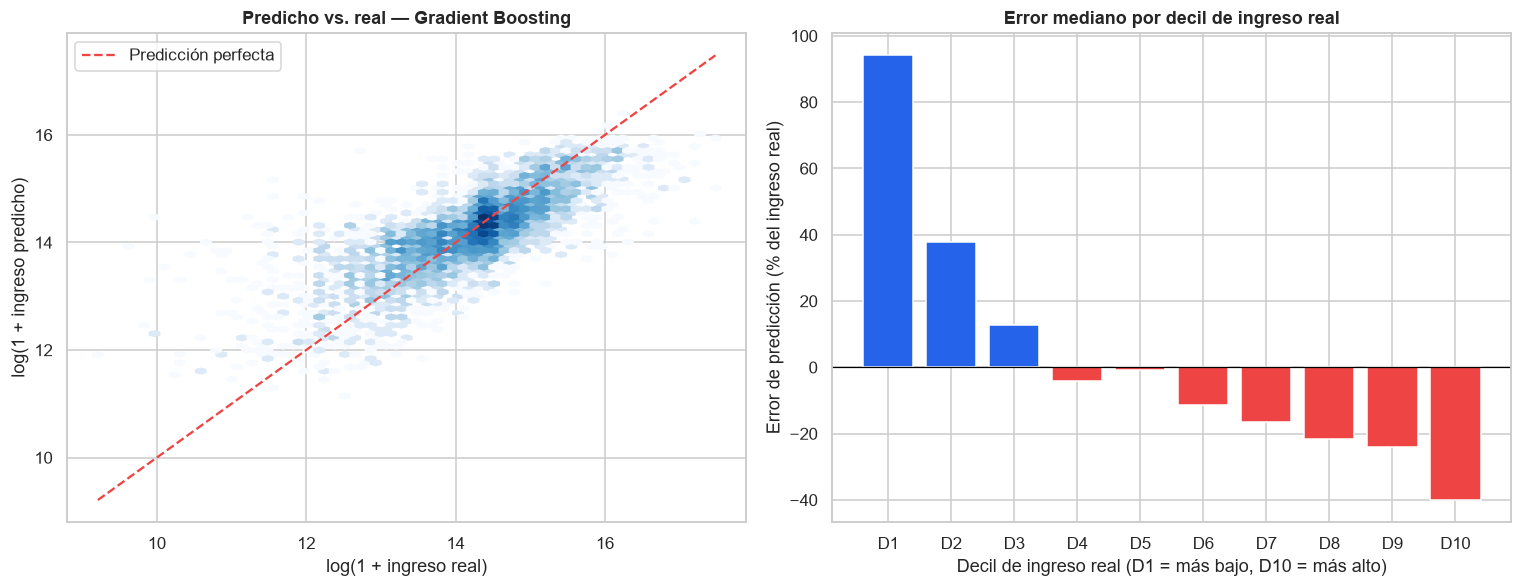

,ingreso_min,ingreso_max,error_mediano_pct
decil,,,
D1,"$10,000","$500,000",+94.1 %
D2,"$520,000","$800,000",+37.8 %
D3,"$810,000","$1,200,000",+12.9 %
D4,"$1,220,000","$1,550,000",-4.1 %
D5,"$1,560,000","$1,750,905",-0.8 %
D6,"$1,750,909","$2,000,000",-11.3 %
D7,"$2,000,950","$2,100,000",-16.4 %
D8,"$2,110,905","$2,800,000",-21.5 %
D9,"$2,820,000","$4,000,000",-23.9 %


In [15]:
# GEIH_2026: el mejor modelo es el de menor RMSE en test (primera fila de la tabla ordenada)
GEIH_2026_MEJOR = geih_2026_df_metricas.index[0]
geih_2026_real_cop = np.expm1(y_test).to_numpy()
geih_2026_pred_cop = np.expm1(geih_2026_pred_test[GEIH_2026_MEJOR])
print("Modelo con mejor desempeño:", GEIH_2026_MEJOR)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
# GEIH_2026: predicho vs real en log (la escala del modelo); la diagonal es la predicción perfecta
axes[0].hexbin(y_test, geih_2026_pred_test[GEIH_2026_MEJOR], gridsize=60, cmap="Blues", mincnt=1, bins="log")
_lim = [y_test.min(), y_test.max()]
axes[0].plot(_lim, _lim, color="#ef4444", linestyle="--", label="Predicción perfecta")
axes[0].set_title(f"Predicho vs. real — {GEIH_2026_MEJOR}")
axes[0].set_xlabel("log(1 + ingreso real)")
axes[0].set_ylabel("log(1 + ingreso predicho)")
axes[0].legend(loc="upper left")

# GEIH_2026: error porcentual mediano por decil de ingreso real (¿a quién le predice peor?)
geih_2026_df_err = pd.DataFrame({"real": geih_2026_real_cop, "pred": geih_2026_pred_cop})
geih_2026_df_err["decil"] = pd.qcut(geih_2026_df_err["real"], 10, labels=[f"D{i}" for i in range(1, 11)])
geih_2026_df_err["error_pct"] = (geih_2026_df_err["pred"] - geih_2026_df_err["real"]) / geih_2026_df_err["real"] * 100
geih_2026_err_decil = geih_2026_df_err.groupby("decil", observed=True)["error_pct"].median()
axes[1].bar(geih_2026_err_decil.index.astype(str), geih_2026_err_decil.values,
            color=["#ef4444" if v < 0 else "#2563eb" for v in geih_2026_err_decil.values])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Error mediano por decil de ingreso real")
axes[1].set_xlabel("Decil de ingreso real (D1 = más bajo, D10 = más alto)")
axes[1].set_ylabel("Error de predicción (% del ingreso real)")
plt.tight_layout()
plt.savefig("geih_2026_predicho_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

# GEIH_2026: rango de ingreso de cada decil, para leer la figura en pesos
geih_2026_df_err.groupby("decil", observed=True).agg(
    ingreso_min=("real", "min"), ingreso_max=("real", "max"), error_mediano_pct=("error_pct", "median")
).style.format({"ingreso_min": "${:,.0f}", "ingreso_max": "${:,.0f}", "error_mediano_pct": "{:+.1f} %"})

**Insight:** las predicciones siguen la diagonal, pero **comprimidas hacia el centro**. El modelo acierta muy bien en la mitad de la distribución (deciles D4–D5, entre $1,2 y $1,75 millones, con error mediano de −4 % y −1 %). En cambio, **sobrestima los ingresos bajos** (en D1, ingresos de hasta $500 mil, predice casi el doble) y **subestima los altos** (en D10, de $4 millones en adelante, predice un 40 % menos). Es la regresión a la media típica cuando faltan variables que expliquen los extremos: con edad, educación y horas no se puede distinguir a un médico especialista de un profesional recién graduado, ni a un trabajador por días de uno a destajo. Para el negocio: el modelo sirve para estimar ingresos **típicos** de un perfil, no para detectar a quienes ganan muy poco o muchísimo.

### Importancia de variables

Se usa **importancia por permutación en test**: se desordena una variable y se mide cuánto empeora el RMSE. Sirve para cualquier modelo y, al calcularse en test, mide lo que el modelo realmente usa para generalizar. Las dummies de departamento se agrupan en una sola variable "departamento" (se desordenan juntas) para que su efecto no quede repartido en 32 columnas pequeñas.

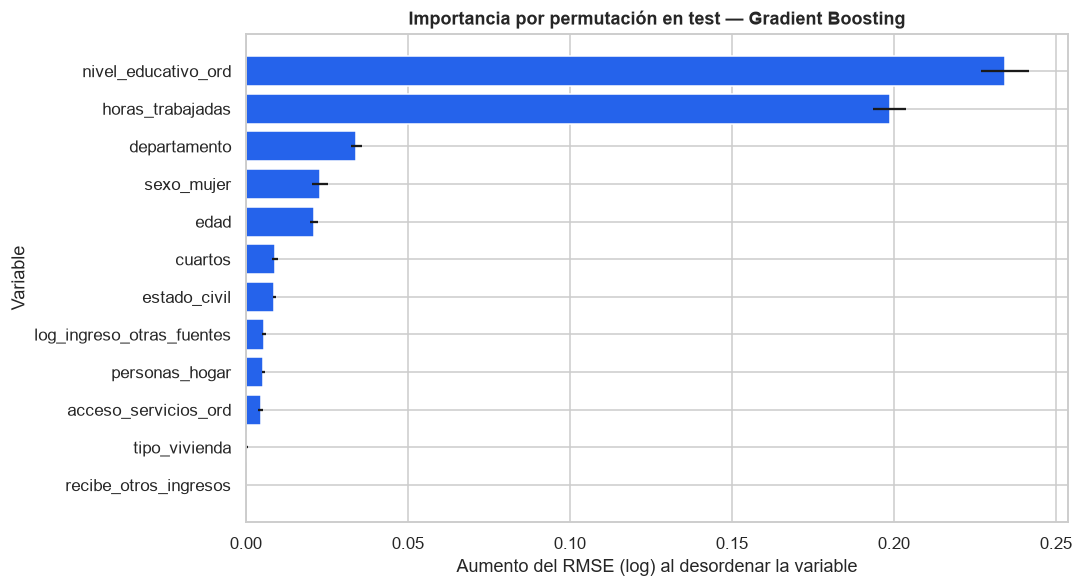

In [16]:
def geih_2026_importancia_agrupada(modelo, X, y, grupos, repeticiones=5):
    '''GEIH_2026: importancia por permutación por GRUPO de columnas: desordena juntas las columnas de cada grupo
    (p. ej., todas las dummies de departamento) y mide el aumento del RMSE en log. Devuelve media y desviación.'''
    rng = np.random.default_rng(GEIH_2026_SEMILLA)
    base = np.sqrt(mean_squared_error(y, modelo.predict(X)))
    filas = []
    for grupo, cols in grupos.items():
        aumentos = []
        for _ in range(repeticiones):
            Xp = X.copy()
            Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]   # misma permutación para todo el grupo
            aumentos.append(np.sqrt(mean_squared_error(y, modelo.predict(Xp))) - base)
        filas.append({"variable": grupo, "aumento_rmse": np.mean(aumentos), "desv": np.std(aumentos)})
    return pd.DataFrame(filas).set_index("variable").sort_values("aumento_rmse", ascending=False)

# GEIH_2026: grupos = cada variable original (las dummies de una misma categórica van juntas)
geih_2026_grupos = {}
for c in geih_2026_predictoras:
    base = next((p for p in ("departamento", "estado_civil", "tipo_vivienda") if c.startswith(p + "_")), c)
    geih_2026_grupos.setdefault(base, []).append(c)

geih_2026_df_imp = geih_2026_importancia_agrupada(geih_2026_modelos[GEIH_2026_MEJOR], X_test, y_test, geih_2026_grupos)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(geih_2026_df_imp.index, geih_2026_df_imp["aumento_rmse"], xerr=geih_2026_df_imp["desv"], color="#2563eb")
ax.invert_yaxis()
ax.set_title(f"Importancia por permutación en test — {GEIH_2026_MEJOR}")
ax.set_xlabel("Aumento del RMSE (log) al desordenar la variable")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.savefig("geih_2026_importancia_variables.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** el ingreso lo explican sobre todo **dos variables**: el **nivel educativo** (al desordenarlo, el RMSE sube 0,23) y las **horas trabajadas** (0,20), muy por encima del resto. Después vienen el **departamento**, el **sexo** y la **edad**, con efectos menores pero claros. Las características de la vivienda (cuartos, servicios, tipo) casi no aportan una vez que se conoce la educación de la persona. Esto coincide con lo visto en la Fase A: la educación es la palanca más fuerte del ingreso laboral, y la brecha por sexo **se mantiene incluso controlando por educación, horas y región**.

### Lectura de la Regresión Lineal

Aunque predice peor, la regresión lineal es el modelo más fácil de explicar. Como el objetivo está en log, un coeficiente `b` se traduce en un efecto de **(e^b − 1) × 100 %** sobre el ingreso, manteniendo lo demás constante. Para las variables escaladas, el efecto corresponde a **una unidad del escalador** (una desviación estándar en edad y educación, o un IQR en horas).

In [17]:
# GEIH_2026: coeficientes de la regresión lineal convertidos a efecto porcentual sobre el ingreso
geih_2026_lin = geih_2026_modelos["Regresión Lineal"]
geih_2026_coef = pd.Series(geih_2026_lin.named_steps["modelo"].coef_,
                           index=geih_2026_lin.named_steps["pre"].get_feature_names_out())
geih_2026_efecto = ((np.exp(geih_2026_coef) - 1) * 100).rename("efecto_%")

# GEIH_2026: unidad del escalador para cada variable numérica (para poder leer el efecto en unidades reales)
_pre = geih_2026_lin.named_steps["pre"]
_unidad = {}
for nombre_t, esc, cols in _pre.transformers_:
    if nombre_t == "robusto":
        _unidad.update({c: f"+{s:.1f} (1 IQR)" for c, s in zip(cols, esc.scale_)})
    elif nombre_t == "estandar":
        _unidad.update({c: f"+{s:.2f} (1 desv. est.)" for c, s in zip(cols, esc.scale_)})
    elif nombre_t == "minmax":
        _unidad.update({c: f"+{1 / s:.1f} (todo el rango)" for c, s in zip(cols, esc.scale_)})

geih_2026_num_lin = ["edad", "nivel_educativo_ord", "horas_trabajadas", "acceso_servicios_ord",
                     "cuartos", "personas_hogar", "log_ingreso_otras_fuentes", "recibe_otros_ingresos", "sexo_mujer"]
geih_2026_df_coef = pd.DataFrame({"cambio en la variable": pd.Series(_unidad).reindex(geih_2026_num_lin).fillna("de 0 a 1"),
                                  "efecto_%": geih_2026_efecto.reindex(geih_2026_num_lin)})
geih_2026_df_coef.style.format({"efecto_%": "{:+.1f} %"})

,cambio en la variable,efecto_%
edad,+13.99 (1 desv. est.),+2.4 %
nivel_educativo_ord,+1.54 (1 desv. est.),+54.3 %
horas_trabajadas,+8.0 (1 IQR),+21.2 %
acceso_servicios_ord,+0.47 (1 desv. est.),+1.9 %
cuartos,+1.0 (1 IQR),+8.7 %
personas_hogar,+2.0 (1 IQR),-7.7 %
log_ingreso_otras_fuentes,+18.9 (todo el rango),-73.4 %
recibe_otros_ingresos,de 0 a 1,+162.6 %
sexo_mujer,de 0 a 1,-19.7 %


**Insight:** manteniendo todo lo demás constante, una desviación estándar más de nivel educativo (≈ 1,5 escalones, por ejemplo de Media a Universitario) se asocia con un **ingreso ≈ 54 % mayor**, y 8 horas semanales más con un **≈ 21 % más**. **Ser mujer se asocia con un ingreso ≈ 20 % menor** a igual educación, edad, horas, departamento y hogar, que es la misma brecha que muestra la importancia de variables del modelo de árboles. Los coeficientes de `recibe_otros_ingresos` y `log_ingreso_otras_fuentes` no deben leerse por separado: describen la misma información (si recibe y cuánto) y se compensan entre sí.

## 6. Modelo no supervisado: segmentación de trabajadores con K-Means

**Objetivo de negocio:** encontrar perfiles de trabajadores que se parezcan entre sí, sin decirle al algoritmo qué buscar. Esto sirve, por ejemplo, para diseñar programas de formación o de empleo por segmento.

**Variables:** `edad`, `horas_trabajadas`, `nivel_educativo_ord` y `log_ingreso_laboral`. Se eligen pocas variables y con significado claro para que los segmentos se puedan describir. Las dummies de departamento se dejan fuera porque, en un algoritmo de distancias, 32 columnas binarias dominarían el resultado y los grupos serían solo "regiones".

**Sin leakage:** el `StandardScaler` y K-Means se ajustan con train; las métricas (Silhouette y Davies-Bouldin) se calculan sobre **test**, con los centroides aprendidos en train.

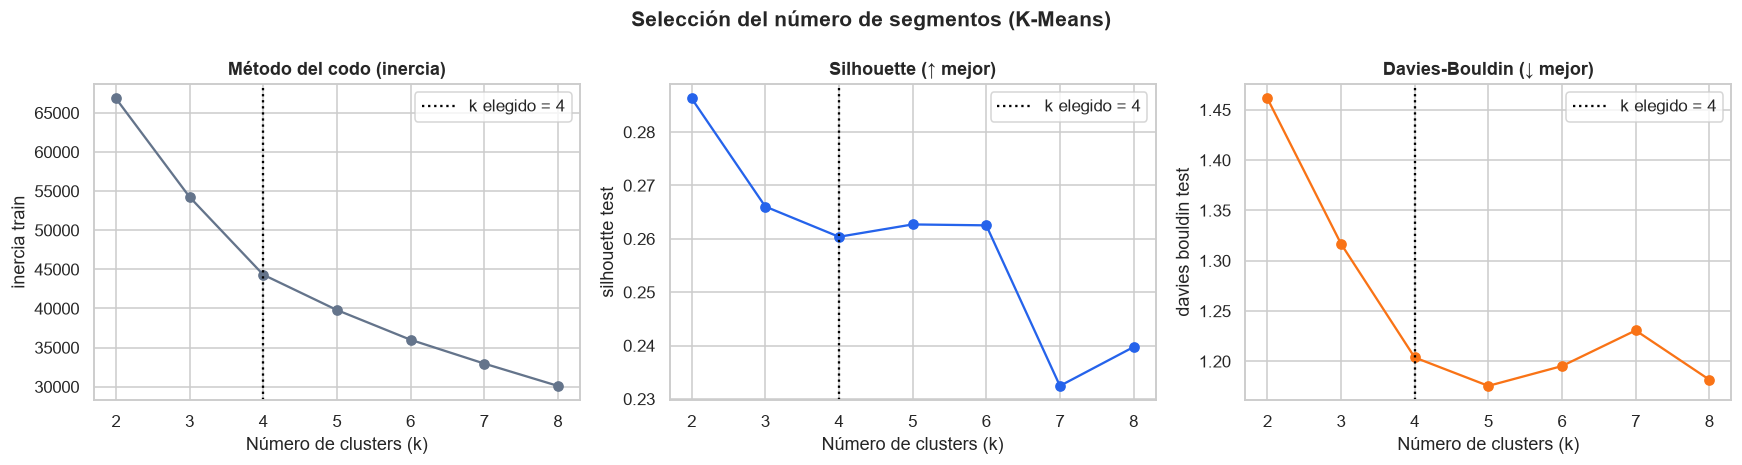

,inercia_train,silhouette_test,davies_bouldin_test,tamaño_menor_%
k,,,,
2,66841.295,0.286,1.461,34.912
3,54245.874,0.266,1.317,15.547
4,44315.974,0.260,1.204,13.170
5,39805.371,0.263,1.176,8.225
6,36002.263,0.263,1.195,7.479
7,32961.607,0.232,1.231,6.976
8,30108.775,0.240,1.182,6.663


In [18]:
# GEIH_2026: datos para clustering (mismas filas y misma partición que los modelos supervisados)
GEIH_2026_COLS_CLUSTER = ["edad", "horas_trabajadas", "nivel_educativo_ord", "log_ingreso_laboral"]
geih_2026_escalador_cl = StandardScaler().fit(geih_2026_df_modelo.loc[geih_2026_es_train, GEIH_2026_COLS_CLUSTER])
geih_2026_Z_train = geih_2026_escalador_cl.transform(geih_2026_df_modelo.loc[geih_2026_es_train, GEIH_2026_COLS_CLUSTER])
geih_2026_Z_test = geih_2026_escalador_cl.transform(geih_2026_df_modelo.loc[~geih_2026_es_train, GEIH_2026_COLS_CLUSTER])

# GEIH_2026: búsqueda de k con método del codo (inercia), Silhouette (más alto es mejor) y Davies-Bouldin (más bajo es mejor)
geih_2026_filas_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=GEIH_2026_SEMILLA).fit(geih_2026_Z_train)
    etiquetas = km.predict(geih_2026_Z_test)
    geih_2026_filas_k.append({"k": k, "inercia_train": km.inertia_,
                              "silhouette_test": silhouette_score(geih_2026_Z_test, etiquetas),
                              "davies_bouldin_test": davies_bouldin_score(geih_2026_Z_test, etiquetas),
                              "tamaño_menor_%": np.bincount(etiquetas).min() / len(etiquetas) * 100})
geih_2026_df_k = pd.DataFrame(geih_2026_filas_k).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, col, titulo, color in zip(axes, ["inercia_train", "silhouette_test", "davies_bouldin_test"],
                                  ["Método del codo (inercia)", "Silhouette (↑ mejor)", "Davies-Bouldin (↓ mejor)"],
                                  ["#64748b", "#2563eb", "#f97316"]):
    ax.plot(geih_2026_df_k.index, geih_2026_df_k[col], marker="o", color=color)
    ax.axvline(4, color="black", linestyle=":", label="k elegido = 4")
    ax.set_title(titulo)
    ax.set_xlabel("Número de clusters (k)")
    ax.set_ylabel(col.replace("_", " "))
    ax.legend()
fig.suptitle("Selección del número de segmentos (K-Means)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("geih_2026_kmeans_seleccion_k.png", dpi=150, bbox_inches="tight")
plt.show()
geih_2026_df_k.round(3)

**Insight:** no hay un codo marcado, algo normal en datos socioeconómicos donde los perfiles se mezclan de forma gradual. Se elige **k = 4** porque:
- Davies-Bouldin baja con fuerza hasta k = 4 (de 1,46 a 1,20) y después casi no mejora (1,18 con k = 5).
- El Silhouette se mantiene prácticamente igual entre k = 3 y k = 6 (0,26–0,27).
- Con k = 4 el segmento más pequeño reúne el 13 % de las personas. Con k = 5 aparece un grupo de solo el 8 %, más difícil de usar en la práctica.

k = 2 tiene el mejor Silhouette, pero dos grupos ("gana más / gana menos") no agregan nada que no se sepa ya.

In [19]:
# GEIH_2026: modelo final de clustering con k = 4, ajustado con train y aplicado a train y test
GEIH_2026_K = 4
geih_2026_kmeans = KMeans(n_clusters=GEIH_2026_K, n_init=10, random_state=GEIH_2026_SEMILLA).fit(geih_2026_Z_train)
geih_2026_df_modelo["cluster"] = -1
geih_2026_df_modelo.loc[geih_2026_es_train, "cluster"] = geih_2026_kmeans.labels_
geih_2026_df_modelo.loc[~geih_2026_es_train, "cluster"] = geih_2026_kmeans.predict(geih_2026_Z_test)
geih_2026_et_test = geih_2026_df_modelo.loc[~geih_2026_es_train, "cluster"].to_numpy()

# GEIH_2026: comparación con clustering jerárquico (Ward) en una muestra de test (es O(n²), no escala a 28 mil filas)
_rng = np.random.default_rng(GEIH_2026_SEMILLA)
_idx = _rng.choice(len(geih_2026_Z_test), size=min(4000, len(geih_2026_Z_test)), replace=False)
geih_2026_jer = AgglomerativeClustering(n_clusters=GEIH_2026_K, linkage="ward").fit_predict(geih_2026_Z_test[_idx])

geih_2026_df_cluster_metricas = pd.DataFrame({
    "K-Means (test completo)": {"Silhouette": silhouette_score(geih_2026_Z_test, geih_2026_et_test),
                                "Davies-Bouldin": davies_bouldin_score(geih_2026_Z_test, geih_2026_et_test)},
    "K-Means (misma muestra)": {"Silhouette": silhouette_score(geih_2026_Z_test[_idx], geih_2026_et_test[_idx]),
                                "Davies-Bouldin": davies_bouldin_score(geih_2026_Z_test[_idx], geih_2026_et_test[_idx])},
    "Jerárquico Ward (muestra)": {"Silhouette": silhouette_score(geih_2026_Z_test[_idx], geih_2026_jer),
                                  "Davies-Bouldin": davies_bouldin_score(geih_2026_Z_test[_idx], geih_2026_jer)},
}).T.round(3)
geih_2026_df_cluster_metricas

,Silhouette,Davies-Bouldin
K-Means (test completo),0.260,1.204
K-Means (misma muestra),0.261,1.202
Jerárquico Ward (muestra),0.219,1.375


In [20]:
# GEIH_2026: perfil de cada segmento en unidades reales (pesos, años, horas), calculado con train
_perfil_base = geih_2026_df_modelo[geih_2026_es_train]
geih_2026_perfil = _perfil_base.groupby("cluster").agg(
    personas=("id_hecho", "size"),
    edad_media=("edad", "mean"),
    horas_mediana=("horas_trabajadas", "median"),
    nivel_educativo_medio=("nivel_educativo_ord", "mean"),
    ingreso_mediano=("ingreso_laboral", "median"),
    pct_mujeres=("sexo_mujer", "mean"),
    pct_acceso_completo=("acceso_servicios_ord", lambda s: (s == 2).mean()),
)
geih_2026_perfil["pct_personas"] = geih_2026_perfil["personas"] / geih_2026_perfil["personas"].sum()

# GEIH_2026: nombre de negocio para cada segmento según su ingreso y educación relativos (se asigna por ranking, no a mano)
GEIH_2026_ESCALA_EDU = ["Sin educación", "Primaria", "Secundaria", "Media", "Técnico/Tecnológico", "Universitario", "Posgrado"]
def geih_2026_nombrar_segmento(fila, perfil):
    '''GEIH_2026: genera un nombre corto para el segmento a partir de su posición en ingreso, edad y horas.'''
    partes = []
    partes.append("Ingreso alto" if fila["ingreso_mediano"] == perfil["ingreso_mediano"].max()
                  else "Ingreso bajo" if fila["ingreso_mediano"] == perfil["ingreso_mediano"].min() else "Ingreso medio")
    partes.append("jóvenes" if fila["edad_media"] == perfil["edad_media"].min()
                  else "mayores" if fila["edad_media"] == perfil["edad_media"].max() else "edad media")
    if fila["horas_mediana"] < 30:
        partes.append("tiempo parcial")
    return ", ".join(partes)

geih_2026_perfil["segmento"] = [geih_2026_nombrar_segmento(f, geih_2026_perfil) for _, f in geih_2026_perfil.iterrows()]
geih_2026_perfil["educación típica"] = geih_2026_perfil["nivel_educativo_medio"].round().astype(int).map(
    dict(enumerate(GEIH_2026_ESCALA_EDU)))
geih_2026_perfil.style.format({
    "personas": "{:,}", "edad_media": "{:.1f}", "horas_mediana": "{:.0f}", "nivel_educativo_medio": "{:.2f}",
    "ingreso_mediano": "${:,.0f}", "pct_mujeres": "{:.0%}", "pct_acceso_completo": "{:.0%}", "pct_personas": "{:.0%}"})

,personas,edad_media,horas_mediana,nivel_educativo_medio,ingreso_mediano,pct_mujeres,pct_acceso_completo,pct_personas,segmento,educación típica
cluster,,,,,,,,,,
0,"5,651",42.4,44,5.07,"$3,400,000",52%,82%,25%,"Ingreso alto, edad media",Universitario
1,"2,925",43.9,20,2.60,"$400,000",71%,62%,13%,"Ingreso bajo, edad media, tiempo parcial",Media
2,"5,933",55.4,48,1.79,"$1,500,000",32%,63%,26%,"Ingreso medio, mayores",Secundaria
3,"8,488",30.9,46,3.14,"$1,750,095",40%,69%,37%,"Ingreso medio, jóvenes",Media


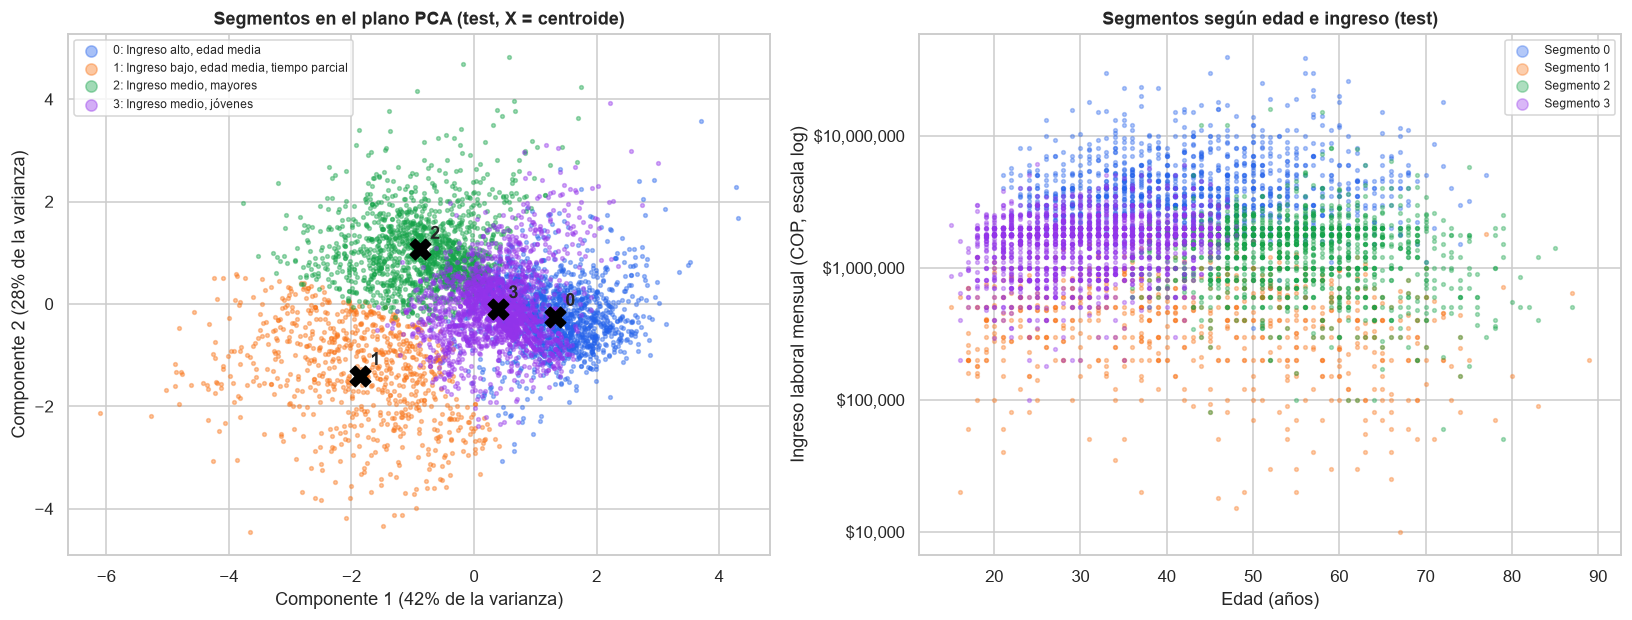

In [21]:
# GEIH_2026: visualización de los segmentos. PCA (ajustado con train) reduce las 4 variables a 2 ejes
geih_2026_pca = PCA(n_components=2, random_state=GEIH_2026_SEMILLA).fit(geih_2026_Z_train)
geih_2026_P_test = geih_2026_pca.transform(geih_2026_Z_test)
geih_2026_paleta = ["#2563eb", "#f97316", "#16a34a", "#9333ea", "#dc2626", "#0891b2"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for c in range(GEIH_2026_K):
    _m = geih_2026_et_test == c
    axes[0].scatter(geih_2026_P_test[_m, 0], geih_2026_P_test[_m, 1], s=6, alpha=0.4,
                    color=geih_2026_paleta[c], label=f"{c}: {geih_2026_perfil.loc[c, 'segmento']}")
# GEIH_2026: centroides marcados con el número del segmento (fuera de la leyenda para que no se deforme)
_cent = geih_2026_pca.transform(geih_2026_kmeans.cluster_centers_)
for c, (x, y) in enumerate(_cent):
    axes[0].scatter(x, y, marker="X", s=180, color="black")
    axes[0].annotate(str(c), (x, y), xytext=(7, 7), textcoords="offset points", fontweight="bold")
_var = geih_2026_pca.explained_variance_ratio_
axes[0].set_title("Segmentos en el plano PCA (test, X = centroide)")
axes[0].set_xlabel(f"Componente 1 ({_var[0]:.0%} de la varianza)")
axes[0].set_ylabel(f"Componente 2 ({_var[1]:.0%} de la varianza)")
axes[0].legend(fontsize=8, markerscale=3, loc="upper left")

# GEIH_2026: misma segmentación en variables de negocio: edad vs. ingreso
_test = geih_2026_df_modelo[~geih_2026_es_train]
for c in range(GEIH_2026_K):
    _d = _test[_test["cluster"] == c]
    axes[1].scatter(_d["edad"], _d["ingreso_laboral"], s=6, alpha=0.35, color=geih_2026_paleta[c], label=f"Segmento {c}")
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(GEIH_2026_COP)
axes[1].set_title("Segmentos según edad e ingreso (test)")
axes[1].set_xlabel("Edad (años)")
axes[1].set_ylabel("Ingreso laboral mensual (COP, escala log)")
axes[1].legend(fontsize=8, markerscale=3)
plt.tight_layout()
plt.savefig("geih_2026_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** K-Means separa **cuatro perfiles de trabajadores** con sentido de negocio (cifras de train):

| Segmento | % de ocupados | Perfil |
|---|---|---|
| 0 · Ingreso alto, edad media | 25 % | ~42 años, educación universitaria, 44 h/semana, ingreso mediano **$3,4 millones**; 82 % con todos los servicios en la vivienda |
| 1 · Ingreso bajo, tiempo parcial | 13 % | ~44 años, educación media, **20 h/semana**, ingreso mediano **$400 mil**; **71 % mujeres** |
| 2 · Ingreso medio, mayores | 26 % | ~55 años, educación hasta secundaria, 48 h/semana, ingreso mediano $1,5 millones; 68 % hombres |
| 3 · Ingreso medio, jóvenes | 37 % | ~31 años, educación media, 46 h/semana, ingreso mediano $1,75 millones |

El hallazgo más útil es el **segmento 1**: un grupo mayoritariamente femenino que trabaja pocas horas y gana muy poco. Allí se concentra el subempleo, y es el candidato natural para programas de empleo de jornada completa o de cuidado infantil. El segmento 2 (mayores con baja educación y jornadas largas) apunta a temas de pensión y protección en la vejez.

En calidad, K-Means (Silhouette 0,26; Davies-Bouldin 1,20 en test) **supera al clustering jerárquico de Ward** sobre la misma muestra (0,22 y 1,38), y además escala a las 28 mil filas y permite asignar personas nuevas a un segmento. Un Silhouette de 0,26 indica grupos con fronteras difusas, lo esperable cuando el ingreso y la edad varían de forma continua. Por eso los segmentos deben leerse como perfiles típicos y no como categorías tajantes.

## 7. Elección del modelo final y conclusiones

In [22]:
# GEIH_2026: tabla resumen para el documento (las 4 métricas pedidas + lectura en pesos)
geih_2026_resumen = geih_2026_df_metricas[["MSE (log)", "RMSE (log)", "MAE (log)", "R² (log)", "MAE (COP)",
                                           "Error mediano (COP)", "Tiempo de entrenamiento (s)"]].copy()
geih_2026_resumen["R² CV media (train)"] = geih_2026_df_cv["R² CV media"]
geih_2026_resumen.style.format({
    "MSE (log)": "{:.4f}", "RMSE (log)": "{:.4f}", "MAE (log)": "{:.4f}", "R² (log)": "{:.3f}",
    "MAE (COP)": "${:,.0f}", "Error mediano (COP)": "${:,.0f}", "Tiempo de entrenamiento (s)": "{:.1f}",
    "R² CV media (train)": "{:.3f}"}, na_rep="—")

,MSE (log),RMSE (log),MAE (log),R² (log),MAE (COP),Error mediano (COP),Tiempo de entrenamiento (s),R² CV media (train)
Gradient Boosting,0.3351,0.5789,0.4065,0.587,"$810,427","$411,311",8.7,0.562
Random Forest,0.3451,0.5875,0.4125,0.575,"$815,319","$418,382",1.3,0.548
Red Neuronal (MLP),0.3608,0.6006,0.4269,0.556,"$844,169","$464,654",3.4,0.519
Regresión Lineal,0.4337,0.6586,0.4788,0.466,"$954,735","$522,760",0.0,0.455
Línea base (mediana),0.8328,0.9126,0.6298,-0.026,"$1,181,808","$750,905",0.0,—


### Modelo elegido: **Gradient Boosting** (`HistGradientBoostingRegressor`)

**Por qué (en orden de peso):**
1. **Precisión:** es el mejor en las cuatro métricas pedidas en test (MSE 0,335; RMSE 0,579; MAE 0,407; R² 0,587) y en la validación cruzada en train (R² 0,563 ± 0,009), así que la ventaja no depende de la partición.
2. **Generalización:** su brecha train–test (0,623 → 0,587) es mucho menor que la de Random Forest (0,707 → 0,575). Generaliza mejor y sobreajusta menos.
3. **Costo razonable:** entrena en segundos y no necesita escalado. Sus hiperparámetros se eligieron con validación cruzada sobre train, sin tocar test.

**Lo que se sacrifica es interpretabilidad.** Por eso se usan dos apoyos: la **importancia por permutación**, que muestra qué variables usa, y la **Regresión Lineal** como modelo explicativo, que traduce cada variable a un efecto porcentual. Si el uso final exigiera explicar cada predicción a un tercero (por ejemplo, ante una entidad pública), la regresión lineal sería la alternativa: pierde ≈ 12 puntos de R² a cambio de una fórmula transparente.

**Random Forest** queda como alternativa casi equivalente (diferencia de MAE de solo ≈ $4 mil), pero sobreajusta más y no ofrece ninguna ventaja.

### Conclusiones
- Con variables sociodemográficas básicas se explica **cerca del 59 % de la variación del log-ingreso**. El error típico es de ±40–50 % del ingreso, aceptable para estimar ingresos de un **perfil** pero no de una persona puntual.
- **Educación y horas trabajadas** explican la mayor parte del ingreso. La **brecha por sexo (~20 %)** persiste aun a igual educación, edad, horas y región.
- El modelo **comprime los extremos**: sobrestima los ingresos más bajos y subestima los más altos.
- La segmentación muestra un grupo de **trabajadoras a tiempo parcial con ingresos muy bajos** (13 % de los ocupados), que es el foco natural de política de empleo.

### Posibles mejoras
- **Más variables:** ocupación, rama de actividad, posición ocupacional (asalariado/independiente), tamaño de la empresa y formalidad (cotiza a pensión). Son justo las que separan los ingresos extremos que hoy el modelo no distingue, y están en otros módulos de la GEIH.
- **Más datos:** unir varios meses de la GEIH para tener más casos en departamentos pequeños y en los ingresos altos.
- **Hiperparámetros:** una búsqueda más amplia (`RandomizedSearchCV`) para Gradient Boosting y la red neuronal.
- **Otros algoritmos u objetivos:** LightGBM o XGBoost; regresión por cuantiles para dar un **rango** de ingreso en lugar de un solo valor; o un modelo de clasificación por tramos de ingreso si al negocio le basta con saber si alguien está por debajo del salario mínimo.

In [23]:
# GEIH_2026: las figuras y la tabla de métricas quedan en la carpeta desde donde se ejecuta el notebook
print("Figuras y tabla guardadas en:", os.path.abspath("."))

Figuras y tabla guardadas en: C:\Users\velez\Proyecto-1-ICD\entrega 2
